# Sales Analysis - AAL Q4 2020

### Notebook setup

This notebook was written and run in Google Colab, which uses the standard
Jupyter notebook format (.ipynb). Code cells, Markdown cells and the figures
they produce are all held together in the one file.

The analysis covers 1 Oct to 30 Dec 2020 across seven Australian states, with 31 Oct 2020 absent from the source. It works through data wrangling, data analysis, time analysis, data visualisation and the closing recommendations.




### Step 1(a) - Data inspection

The dataset is loaded and inspected before anything is changed. The aim is to
find missing values and incorrect entries.

Missing values are checked with both isna() and notna(), so the table is read
from two directions rather than one. Duplicate rows and the structure of the
table are checked as well, to confirm the data is complete.

The text columns and the Date column are also printed, to check the values are
consistent and ready for grouping and time analysis.


In [49]:
import numpy as np
import pandas as pd

df = pd.read_csv("AusApparalSales4thQrt2020.csv")

print(df.shape)
print(df.head())
print(df.dtypes)

# missing value check
print(df.isna().sum())
print("missing values total:", df.isna().sum().sum())
print("non-missing values total:", df.notna().sum().sum())

# incorrect entries in the text columns
for col in ["Time", "State", "Group"]:
    print(col, "->", df[col].unique())

# duplicates and grain
print("duplicate rows:", df.duplicated().sum())
print("unique dates:", df["Date"].nunique())
print("unique time-state-group combos:", df[["Time", "State", "Group"]].drop_duplicates().shape[0])
print("rows per date:", df.groupby("Date").size().value_counts())


(7560, 6)
         Date        Time State     Group  Unit  Sales
0  1-Oct-2020     Morning    WA      Kids     8  20000
1  1-Oct-2020     Morning    WA       Men     8  20000
2  1-Oct-2020     Morning    WA     Women     4  10000
3  1-Oct-2020     Morning    WA   Seniors    15  37500
4  1-Oct-2020   Afternoon    WA      Kids     3   7500
Date     object
Time     object
State    object
Group    object
Unit      int64
Sales     int64
dtype: object
Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64
missing values total: 0
non-missing values total: 45360
Time -> [' Morning' ' Afternoon' ' Evening']
State -> [' WA' ' NT' ' SA' ' VIC' ' QLD' ' NSW' ' TAS']
Group -> [' Kids' ' Men' ' Women' ' Seniors']
duplicate rows: 0
unique dates: 90
unique time-state-group combos: 84
rows per date: 84    90
Name: count, dtype: int64


### Step 1(a) - Inspection findings

The data has 7560 rows and 6 columns: Date, Time, State, Group, Unit and Sales.

There are no missing values. The isna() check returns zero for every column,
and the total of non-missing values is 45360, which is 7560 rows multiplied by 6 columns. The notna() check confirms the same thing from the other side, so the two functions agree and nothing is hiding in the table.

There are no duplicate rows either.

The structure is a complete grid. There are 90 dates, and 84 combinations of
Time, State and Group, which is 3 times, 7 states and 4 groups. Every date has exactly 84 rows, so no date is short of records.

Two incorrect entries were found, and neither is a missing value:

1. Every value in Time, State and Group starts with a space.
2. Date is text, not a real date, so it would sort alphabetically instead of chronologically.

Both are worth fixing, because the extra space would carry into chart labels
and group names, and the text date would break any time based grouping.


### Step 1(b) - Treatment of incorrect entries

The leading space is stripped from Time, State and Group. The values
themselves are correct, so the rows are repaired rather than dropped. Dropping them would remove the whole dataset, since the problem affects every row.

Date is converted to a real datetime with pd.to_datetime(). The format
%d-%b-%Y matches values such as 1-Oct-2020. Again the values are correct, so
the column is converted instead of removed.

After the conversion, the date range is compared with the number of unique
dates, to check whether every calendar day in the period is actually present.


In [50]:
# strip the leading whitespace from the text columns
for col in ["Time", "State", "Group"]:
    df[col] = df[col].str.strip()

print(df["Time"].unique())
print(df["State"].unique())
print(df["Group"].unique())

# convert Date to a real datetime
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%Y")
print(df["Date"].dtype)
print("min date:", df["Date"].min())
print("max date:", df["Date"].max())

# compare the calendar range with the dates present
full_range = pd.date_range(start=df["Date"].min(), end=df["Date"].max(), freq="D")
present = set(df["Date"].unique())
missing = [d for d in full_range if d not in present]

print("expected days:", len(full_range))
print("days present:", df["Date"].nunique())
print("missing days:", missing)


['Morning' 'Afternoon' 'Evening']
['WA' 'NT' 'SA' 'VIC' 'QLD' 'NSW' 'TAS']
['Kids' 'Men' 'Women' 'Seniors']
datetime64[ns]
min date: 2020-10-01 00:00:00
max date: 2020-12-30 00:00:00
expected days: 91
days present: 90
missing days: [Timestamp('2020-10-31 00:00:00')]


### Step 1(b) - Treatment findings

The text columns are clean now. Time holds Morning, Afternoon and Evening,
State holds the seven states, and Group holds Kids, Men, Women and Seniors,
all without the leading space.

Date is a real datetime now. It runs from 1 Oct 2020 to 30 Dec 2020, which is 91 calendar days, but only 90 dates appear in the data. The one missing day is 31 Oct 2020.

That date needs a decision rather than an unstated fix. It falls on a Saturday, and every other Saturday and Sunday in the period is present. The rest of the grid is complete, with 84 rows on all 90 dates, so this reads as a gap in the extract rather than a day the business closed.

The gap is left as it is and reported. A single absent date in an otherwise complete grid is better stated than estimated, and filling it would add an assumption without adding information.

The gap changes how the months compare, so the coverage of each calendar month is worth stating. October has 31 days and only 30 are present, so one day is missing from October. November has 30 days and all 30 are present. December has 31 days and 30 are present, because the period ends on 30 Dec.


### Step 1(c) - Normalisation

Normalisation is used here rather than standardisation, so that both numeric
columns land on the same 0 to 1 scale and can be compared directly.

Min-Max normalisation rescales a column using:

scaled = (value - minimum) / (maximum - minimum)

This is applied to Sales and Unit. The largest sale in the data becomes 1 and the smallest becomes 0, with all other values sitting in between.

The check afterwards looks at whether Sales and Unit scale in the same
proportion. Sales is Unit multiplied by a price, so if the normalised columns come out identical, then a single fixed price sits behind every row.


In [51]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[["Unit_norm", "Sales_norm"]] = scaler.fit_transform(df[["Unit", "Sales"]])

print(df[["Unit", "Unit_norm", "Sales", "Sales_norm"]].head(10))
print(df[["Unit_norm", "Sales_norm"]].describe())

# do the two columns scale identically?
print("identical after scaling:", df["Unit_norm"].equals(df["Sales_norm"]))
print("max difference:", (df["Unit_norm"] - df["Sales_norm"]).abs().max())

# ratio of Sales to Unit, the average price per unit
print("sales per unit value counts:")
print((df["Sales"] / df["Unit"]).value_counts())


   Unit  Unit_norm  Sales  Sales_norm
0     8   0.095238  20000    0.095238
1     8   0.095238  20000    0.095238
2     4   0.031746  10000    0.031746
3    15   0.206349  37500    0.206349
4     3   0.015873   7500    0.015873
5    10   0.126984  25000    0.126984
6     3   0.015873   7500    0.015873
7    11   0.142857  27500    0.142857
8    15   0.206349  37500    0.206349
9    15   0.206349  37500    0.206349
         Unit_norm   Sales_norm
count  7560.000000  7560.000000
mean      0.254054     0.254054
std       0.204784     0.204784
min       0.000000     0.000000
25%       0.095238     0.095238
50%       0.190476     0.190476
75%       0.380952     0.380952
max       1.000000     1.000000
identical after scaling: False
max difference: 1.1102230246251565e-16
sales per unit value counts:
2500.0    7560
Name: count, dtype: int64


### Step 1(c) - Normalisation findings

Sales and Unit scale almost identically after normalisation, both with a mean of 0.254 and a standard deviation of 0.205.

The two normalised columns are not equal as floating point values, but the
largest difference between them is 1.1e-16. That is rounding error at the limit of a float, not a real difference. Unit and Sales scale in exactly the same
proportion.

The sales per unit check explains why. Sales divided by Unit returns 2500.0 for all 7560 rows, with no other value appearing even once.

Every sale in the dataset is priced at exactly 2500 per unit, so revenue is fully determined by units sold. There is no mix of premium and discounted sales, no price variation between states, and no margin
signal available. There is also no cost column in the data, so margin was never measurable here regardless of price.

The consequence is that the premium versus discount angle is not available.
Whether volume is balanced across states is a separate question, answered in
Step 1(d), and that check shows it is not.


### Step 1(d) - The groupby() function

groupby() splits a table into groups based on one or more columns, applies a
calculation to each group, and returns the results.

In this dataset, groupby() is used for chunking, not merging. Chunking means
breaking one table into smaller pieces that are analysed separately, for
example total Sales per State, or total Unit per Group. Merging is the opposite direction, joining two tables that share a key, for example joining a state sales table to a separate state population table. A key is the shared field a join is built on, such as a state code appearing in
both tables. This dataset holds no second table and no such field, so merging has nothing to act on.

The reason chunking is the right use here is that all six columns already sit in one table at one consistent grain. There is no second table to join, so merging does not apply. Every business question in this project is a
group-then-aggregate question, which is exactly what groupby() does.

A single column can also be grouped by more than one key at once. Grouping by State and Group together gives the state by demographic view, and grouping by State and Time gives the day-part view.

One practical point: groupby() is lazy. It only describes the split until an
aggregation is attached, such as sum(), mean() or size().


In [52]:
# chunking with a single key
print(df.groupby("State")[["Unit", "Sales"]].sum().sort_values("Sales", ascending=False))

print(df.groupby("Group")[["Unit", "Sales"]].sum().sort_values("Sales", ascending=False))

# chunking with two keys at once
state_group = df.groupby(["State", "Group"])[["Unit", "Sales"]].sum()
print(state_group.head(12))

print(state_group.shape)


        Unit      Sales
State                  
VIC    42226  105565000
NSW    29988   74970000
SA     23543   58857500
QLD    13367   33417500
TAS     9104   22760000
NT      9032   22580000
WA      8861   22152500
          Unit     Sales
Group                   
Men      34300  85750000
Women    34177  85442500
Kids     34029  85072500
Seniors  33615  84037500
               Unit     Sales
State Group                  
NSW   Kids     7435  18587500
      Men      7609  19022500
      Seniors  7275  18187500
      Women    7669  19172500
NT    Kids     2280   5700000
      Men      2305   5762500
      Seniors  2186   5465000
      Women    2261   5652500
QLD   Kids     3404   8510000
      Men      3357   8392500
      Seniors  3276   8190000
      Women    3330   8325000
(28, 2)


### Step 1(d) - groupby() findings

Single-key chunking worked as expected. Grouping by State gives seven rows,
grouping by Group gives four rows.

The two-key grouping by State and Group returns 28 rows, which is 7 states
multiplied by 4 groups. That confirms the grid is complete at that level too.

The state totals are not close to equal, which is the opposite of what a
balanced grid would suggest. VIC leads with 105,565,000 in Sales from 42,226
units, while WA sits last with 22,152,500 from 8,861 units. VIC is roughly 4.8 times the size of WA.

The four customer groups, on the other hand, are almost identical. Men lead
with 85,750,000 and Seniors trail with 84,037,500, a gap of only about 2
percent across all four.

So the imbalance lives in the state dimension, not in the demographic
dimension. The groups are evenly spread, but the states are not.


### Step 2(a) - Descriptive statistics on Sales and Unit

Mean, median, mode and standard deviation are reported for both Unit and Sales.

Because Sales is always Unit multiplied by 2500, the two columns carry the same information. Statistics on both are reported, but they tell an identical story, and they are not presented as two separate findings.

Mode is included and assessed rather than trusted. Sales is built from a small set of whole unit counts multiplied by a fixed price, so the most frequent value is a repeat of a common row rather than a centre of the distribution.

Skew is added alongside the four measures, to check whether the distribution is symmetric or pulled to one side.


In [53]:
from scipy import stats

for col in ["Unit", "Sales"]:
    print("---", col)
    print("mean:", df[col].mean())
    print("median:", df[col].median())
    print("mode:", stats.mode(df[col], keepdims=True))
    print("std:", df[col].std())
    print("var:", df[col].var())
    print("skew:", df[col].skew())
    print("min:", df[col].min(), "max:", df[col].max())

print(df["Unit"].value_counts().sort_index())


--- Unit
mean: 18.00542328042328
median: 14.0
mode: ModeResult(mode=array([9]), count=array([406]))
std: 12.901402777586458
var: 166.4461936295156
skew: 1.0855501535060819
min: 2 max: 65
--- Sales
mean: 45013.5582010582
median: 35000.0
mode: ModeResult(mode=array([22500]), count=array([406]))
std: 32253.506943966317
var: 1040288710.1844833
skew: 1.0855501535060816
min: 5000 max: 162500
Unit
2     130
3     240
4     210
5     331
6     370
     ... 
61      9
62     10
63     13
64     13
65     11
Name: count, Length: 64, dtype: int64


### Step 2(a) - Descriptive statistics findings

Unit and Sales return identical skew, 1.086, which confirms the columns carry
the same information at a fixed price of 2500 per unit.

The mean sits above the median in both cases. Unit has a mean of 18.0 against a
median of 14, and Sales has a mean of 45,013 against a median of 35,000. The
gap means the distribution is right skewed, which the skew value of 1.086
agrees with. A minority of high volume rows pull the average up, so the middle
sale is well below the average sale. The median is the better description of a
typical row.

The standard deviation is large relative to the mean. Unit has a standard
deviation of 12.9 against a mean of 18.0, so the spread is about 72 percent of
the average. Sales has a standard deviation of 32,254 against a mean of 45,014,
about 72 percent again. Values range from 5,000 to 162,500, a spread of 32 times
between the smallest and largest sale.

The mode is weak evidence here. Unit mode is 9 and Sales mode is 22,500, both appearing 406 times out of 7,560 rows. That is the most repeated row, not a centre: the median is 14 and the mean is 18, so the mode sits below both.

There are 64 distinct unit values, running 2 to 65. Counts are low at the
bottom, 130 rows at 2 units and 240 at 3, then climb through the middle, 370
rows at 6 units and 331 at 5, and fall away at the top, 9 rows at 61 units. The
shape rises to a peak around 5 to 6 units and then falls away slowly to 65, so
the distribution has a long right tail rather than being symmetric. That tail is
what pulls the mean above the median.


### Step 2(b) - Highest and lowest Group and State

The group with the highest and lowest sales is identified first, then the same comparison across states, since the group view alone does not answer which states generate the most revenue.

For the states, revenue, units and the number of rows per state are all
reported. Revenue and units rank identically because price is fixed at 2500, so those two are one measure reported twice rather than two independent confirmations. The row count is the useful check. If every state carries the same number of rows, then the revenue gap has to come from units per row rather than from more records in the file, and units per row becomes the explanatory variable rather than the total.


In [54]:
# group comparison
group_tot = df.groupby("Group")[["Unit", "Sales"]].sum().sort_values("Sales", ascending=False)
print(group_tot)
print("share of revenue:", (group_tot["Sales"] / group_tot["Sales"].sum() * 100).round(2))

# state comparison, with record count
state_tot = df.groupby("State").agg(
    rows=("Sales", "size"),
    units=("Unit", "sum"),
    sales=("Sales", "sum"),
    units_per_row=("Unit", "mean")
).sort_values("sales", ascending=False)
print(state_tot)
print("share of revenue:", (state_tot["sales"] / state_tot["sales"].sum() * 100).round(2))


          Unit     Sales
Group                   
Men      34300  85750000
Women    34177  85442500
Kids     34029  85072500
Seniors  33615  84037500
share of revenue: Group
Men        25.20
Women      25.11
Kids       25.00
Seniors    24.69
Name: Sales, dtype: float64
       rows  units      sales  units_per_row
State                                       
VIC    1080  42226  105565000      39.098148
NSW    1080  29988   74970000      27.766667
SA     1080  23543   58857500      21.799074
QLD    1080  13367   33417500      12.376852
TAS    1080   9104   22760000       8.429630
NT     1080   9032   22580000       8.362963
WA     1080   8861   22152500       8.204630
share of revenue: State
VIC    31.02
NSW    22.03
SA     17.30
QLD     9.82
TAS     6.69
NT      6.64
WA      6.51
Name: sales, dtype: float64


### Step 2(b) - Highest and lowest Group and State

Group is flat. Men lead with 85,750,000 and Seniors trail with 84,037,500, a
gap of about 2 percent. Revenue shares run 25.20, 25.11, 25.00 and 24.69
percent, so the four groups are evenly spread and no group stands out.

State is not flat. VIC leads with 105,565,000, or 31.02 percent of revenue, and WA trails with 22,152,500, or 6.51 percent. That is a gap of about 4.8 times.

Every state has exactly 1080 rows, so the difference is not more records. It is units per row. VIC averages 39.1 units per row, WA averages 8.2, and the order runs smoothly from VIC down to WA.

Top three states, VIC, NSW and SA, hold 70.35 percent of revenue. The other
four split 29.65 percent. Revenue is concentrated, while the customer mix
within each state stays even.



### Step 2(c) - Testing the state gap

VIC's lead could be a real difference between markets, or it could come from how the dataset was assembled. One check separates the two.

If the states really differ, the gap should hold inside every single date, not just in the total. A daily comparison shows whether VIC leads on each day or whether a few large days create the whole difference.


In [55]:
daily = df.pivot_table(index="Date", columns="State", values="Sales", aggfunc="sum")
print(daily.describe().round(0))

# how often does each state lead on a given day?
print("days VIC is top:", (daily.idxmax(axis=1) == "VIC").sum(), "of", len(daily))
print("days WA is bottom:", (daily.idxmin(axis=1) == "WA").sum(), "of", len(daily))
print((daily.idxmax(axis=1)).value_counts())


State        NSW        NT       QLD        SA       TAS        VIC        WA
count       90.0      90.0      90.0      90.0      90.0       90.0      90.0
mean    833000.0  250889.0  371306.0  653972.0  252889.0  1172944.0  246139.0
std     118864.0   61278.0   92653.0  112835.0   58978.0   200850.0   58617.0
min     595000.0  130000.0  205000.0  460000.0  135000.0   867500.0  137500.0
25%     748125.0  190000.0  295625.0  545000.0  210625.0  1002500.0  188125.0
50%     838750.0  260000.0  362500.0  671250.0  260000.0  1122500.0  256250.0
75%     910000.0  301875.0  460000.0  740000.0  300000.0  1351250.0  290000.0
max    1102500.0  362500.0  540000.0  860000.0  370000.0  1595000.0  360000.0
days VIC is top: 90 of 90
days WA is bottom: 34 of 90
VIC    90
Name: count, dtype: int64


### Step 2(c) - Testing the state gap findings

VIC is the top state on all 90 days. Not most days, every single one. The gap is systematic, not driven by a few large days.

The daily means run in a clean order, VIC 1,172,944 down to WA 246,139, and
each state's daily standard deviation is small next to its mean, so the pattern is stable day to day.

WA is the bottom state on only 34 of 90 days. On the remaining days the lowest spot moves between NT and TAS, which sit close together at means of 250,889 and 252,889. So the top of the table is settled, but the bottom is a lowest tier of three states rather than one clear last place.

The ranges overlap for NSW. NSW's best day of 1,102,500 sits above VIC's
weakest day of 867,500, so those two states cross on individual days. SA, QLD, TAS, NT and WA never reach VIC's floor during the period, so the separation
holds for five of the six other states.


### Step 2(d) - Weekly, monthly and quarterly rollups

Weekly, monthly and quarterly totals are built here, and the charts follow in Step 4.

Week is a Monday to Sunday calendar week, taken from the real datetime column. The first and last weeks are partial because the period starts on 1 Oct and ends on 30 Dec.

The period covers 91 days with 31 Oct missing, so the write up describes it as 1 Oct to 30 Dec rather than a complete quarter.


In [56]:
df["Week"] = df["Date"].dt.to_period("W-SUN")
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

print("--- monthly")
print(df.groupby("Month")[["Unit", "Sales"]].sum())

print("--- weekly")
wk = df.groupby("Week").agg(units=("Unit", "sum"), sales=("Sales", "sum"), days=("Date", "nunique"))
print(wk)

print("--- quarterly")
print(df.groupby("Quarter")[["Unit", "Sales"]].sum())


--- monthly
          Unit      Sales
Month                    
2020-10  45716  114290000
2020-11  36273   90682500
2020-12  54132  135330000
--- weekly
                       units     sales  days
Week                                        
2020-09-28/2020-10-04   6018  15045000     4
2020-10-05/2020-10-11  10801  27002500     7
2020-10-12/2020-10-18  10656  26640000     7
2020-10-19/2020-10-25  10726  26815000     7
2020-10-26/2020-11-01   8723  21807500     6
2020-11-02/2020-11-08   8346  20865000     7
2020-11-09/2020-11-15   8469  21172500     7
2020-11-16/2020-11-22   8445  21112500     7
2020-11-23/2020-11-29   8591  21477500     7
2020-11-30/2020-12-06  11849  29622500     7
2020-12-07/2020-12-13  12610  31525000     7
2020-12-14/2020-12-20  12662  31655000     7
2020-12-21/2020-12-27  12708  31770000     7
2020-12-28/2021-01-03   5517  13792500     3
--- quarterly
           Unit      Sales
Quarter                   
2020Q4   136121  340302500


### Step 2(d) - Rollups findings

December generated the highest revenue at 135,330,000, ahead of October's 114,290,000 and November's 90,682,500. Each month holds 30 days of data, though the calendar months differ in length: October is missing one of its 31, and December is short one day because the period ends on 30 Dec.

October and December are each one day short against November's full 30, so the totals are not directly comparable across the three months. Per day, the order is December strongest, then October, then November.

December looks strongest, and it holds the largest single week of the period.
The week of 21 to 27 December brought in 31,770,000, more than any other week in total, though the final three days of the period are higher per day because that week is incomplete.

Three weeks are incomplete and must not be read as drops. The week to 4 Oct has 4 days, the week to 1 Nov has 6, and the week from 28 Dec has 3. Their low totals are missing days, not falling sales.

Quarter 2020Q4 totals 136,121 units and 340,302,500 in revenue, which is the
same figure as the whole dataset. The quarter label is technically right, but the period is 1 Oct to 30 Dec, not a full quarter.


### Step 2(e) - December lift: broad or concentrated?

December is the strongest month. One question decides how it should be
described. If every state rose in December, the rise is broad. If only some
states rose, it is concentrated. Month by state shows which it is.


In [57]:
ms = df.pivot_table(index="Month", columns="State", values="Sales", aggfunc="sum")
print(ms)
print("December vs October, percent change:")
print(((ms.loc["2020-12"] / ms.loc["2020-10"] - 1) * 100).round(1))


State         NSW       NT       QLD        SA      TAS       VIC       WA
Month                                                                     
2020-10  25007500  8222500  11120000  20610000  8015000  33442500  7872500
2020-11  21490000  5257500   8110000  15532500  5545000  29530000  5217500
2020-12  28472500  9100000  14187500  22715000  9200000  42592500  9062500
December vs October, percent change:
State
NSW    13.9
NT     10.7
QLD    27.6
SA     10.2
TAS    14.8
VIC    27.4
WA     15.1
dtype: float64


### Step 2(e) - December lift findings

December is up in all seven states against October, so the rise appears
everywhere rather than in a few markets.

The size of the rise varies a lot though. QLD is up 27.6 percent and VIC 27.4, while SA is up only 10.2 and NT 10.7. So the direction is shared but the
strength is not.

November falls below October in every state. That gives the quarter a dip in
early November before the December peak, rather than a steady climb.

Two states move together in an obvious way. VIC and QLD are the only ones above 25 percent. That is a two point observation, so it is noted rather than treated as a pattern.


### Step 3(a) - Time of day analysis

Peak and off-peak periods are identified, since day-part timing is what
personalisation and next-best-offer programmes are usually built on.

Time has three values: Morning, Afternoon and Evening. The pattern is checked at national level first, then per state, because a national average can hide states that run on a different pattern.


In [58]:
# national view
time_tot = df.groupby("Time")[["Unit", "Sales"]].sum()
time_tot["share_%"] = (time_tot["Sales"] / time_tot["Sales"].sum() * 100).round(2)
print(time_tot.sort_values("Sales", ascending=False))

# per state
st = df.pivot_table(index="State", columns="Time", values="Sales", aggfunc="sum")
st_pct = (st.div(st.sum(axis=1), axis=0) * 100).round(1)
print(st_pct)


            Unit      Sales  share_%
Time                                
Morning    45683  114207500    33.56
Afternoon  45603  114007500    33.50
Evening    44835  112087500    32.94
Time   Afternoon  Evening  Morning
State                             
NSW         33.5     33.0     33.5
NT          33.3     33.8     33.0
QLD         34.0     31.8     34.2
SA          34.0     32.9     33.1
TAS         33.7     33.2     33.1
VIC         33.2     33.0     33.7
WA          32.9     33.0     34.2


### Step 3(a) - Time of day analysis findings

The national split is almost perfectly flat. Morning holds 33.56 percent of
revenue, Afternoon 33.50 and Evening 32.94. The gap between the best and worst day part is 0.62 percentage points, which is nothing.

The per state view is the same story. Reading across the seven states, the
worst case is WA at 32.9 in the afternoon and the best is QLD at 34.2 in the
morning. Every state sits within roughly one point of an even third.

So there is no peak and no off-peak. Time of day does not separate revenue in this dataset, nationally or by state.

The pattern is uniform across all three checks. A 0.62 point gap is not a
signal, and a day-part programme built on it would be optimising against noise.


### Step 3(b) - Time of day by customer group

The state level check showed a flat pattern, so the same check is run by
customer group. That means the uniformity claim rests on three views rather than one.

A heatmap of percentages is used rather than totals, since totals would only
repeat the group size pattern found earlier.


In [59]:
tg = df.pivot_table(index="Group", columns="Time", values="Sales", aggfunc="sum")
tg_pct = (tg.div(tg.sum(axis=1), axis=0) * 100).round(1)
print(tg_pct)

# spread within each group
print("min and max per group:")
print(pd.DataFrame({"min": tg_pct.min(axis=1), "max": tg_pct.max(axis=1),
                    "spread": (tg_pct.max(axis=1) - tg_pct.min(axis=1)).round(1)}))


Time     Afternoon  Evening  Morning
Group                               
Kids          33.5     33.0     33.5
Men           33.5     32.9     33.5
Seniors       33.6     32.4     34.0
Women         33.4     33.4     33.2
min and max per group:
          min   max  spread
Group                      
Kids     33.0  33.5     0.5
Men      32.9  33.5     0.6
Seniors  32.4  34.0     1.6
Women    33.2  33.4     0.2


### Step 3(b) - Time of day by customer group findings

The group view matches the state view. Spreads run 0.5 points for Kids, 0.6 for Men, 1.6 for Seniors and 0.2 for Women. Every group sits within about a point and a half of an even third.

Seniors are the widest at 1.6 points, from 32.4 in the evening to 34.0 in the morning. That is the largest deviation in the whole check, and it is small enough to be noise rather than a pattern. It is named here so it is not later mistaken for an insight.

Time of day is therefore uniform at national, state and group level. Three
separate checks give the same answer, so the finding rests on more than one
view.


### Step 4(a) - Data visualisation

Seaborn is used for the statistical plots because the figures here are
statistical rather than decorative. The box plot, the distribution plot with its density overlay, and the heatmap for the state by group matrix each need one line in Seaborn, and it applies sensible statistical defaults. Matplotlib would require that logic to be written by hand.

The figures are built in four parts.

- The box plot covers the descriptive statistics from Step 2.
- The dashboard gives the head of Sales and Marketing the state and group view on one screen.
- The distribution plot shows the shape of the unit distribution.
- The daily, weekly, monthly and quarterly charts cover the four time levels.

The four time level charts sit alongside the panels as part of one dashboard set, split across two figures for readability. Monthly is a panel, weekly is plotted with the weekly week length check, and daily and quarterly sit together after it.
Putting thirteen weekly bars, ninety daily points and a single quarterly bar
inside the four panel figure would have cost more in readability than it added.


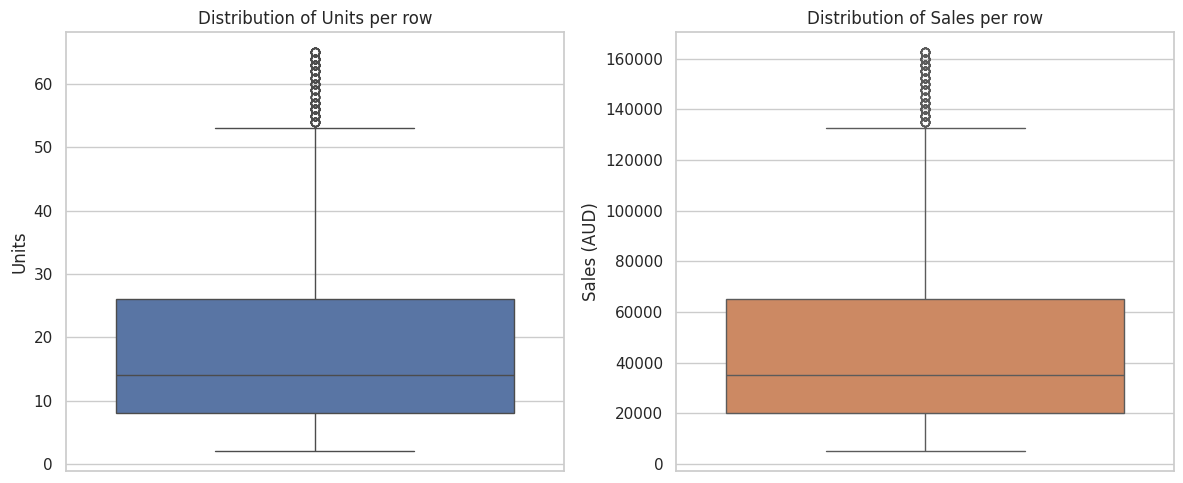

              Unit          Sales
count  7560.000000    7560.000000
mean     18.005423   45013.558201
std      12.901403   32253.506944
min       2.000000    5000.000000
25%       8.000000   20000.000000
50%      14.000000   35000.000000
75%      26.000000   65000.000000
max      65.000000  162500.000000
rows above the 75th percentile: 1831


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Unit"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of Units per row")
axes[0].set_ylabel("Units")

sns.boxplot(y=df["Sales"], ax=axes[1], color="#DD8452")
axes[1].set_title("Distribution of Sales per row")
axes[1].set_ylabel("Sales (AUD)")

plt.tight_layout()
plt.show()

print(df[["Unit", "Sales"]].describe())
print("rows above the 75th percentile:", (df["Unit"] > df["Unit"].quantile(0.75)).sum())


#### Box plot findings

The box plot confirms the Step 2 statistics visually. Both boxes are right
skewed: the median line sits left of the box centre, the upper whisker reaches to about 52 units, and a long column of points sits above it.

The upper whisker stops around 52 while the maximum is 65, so points above 52 are plotted as outliers. That is the high volume tail pulling the mean above the
median, exactly as the skew value of 1.086 suggested.

The interquartile range is wide. Half of all rows fall between 8 and 26 units, which spans 20,000 to 65,000 in revenue. The middle half of the business is spread across a three fold range, so a single average does not describe a typical row well.

Just over 1800 rows sit above the 75th percentile, so the upper quarter of the business is not a few exceptions but a large share of all transactions.

The two panels share the same shape, which is expected when price is fixed at 2500 per unit. Unit and Sales move together because one is the other multiplied by a constant.


#### Dashboard for the head of Sales and Marketing

Four panels, chosen for decisions rather than for volume.

Panel 1: revenue by state, with the share of total shown as a label, so the
ranking and the concentration are readable at a glance.

Panel 2: state by group heatmap. This is the interaction view, and it also shows whether the group mix differs between states at all.

Panel 3: monthly revenue. The weekly view is plotted on its own afterwards,
since the incomplete weeks would distort a shared axis.

Panel 4: time of day, which shows no effect.


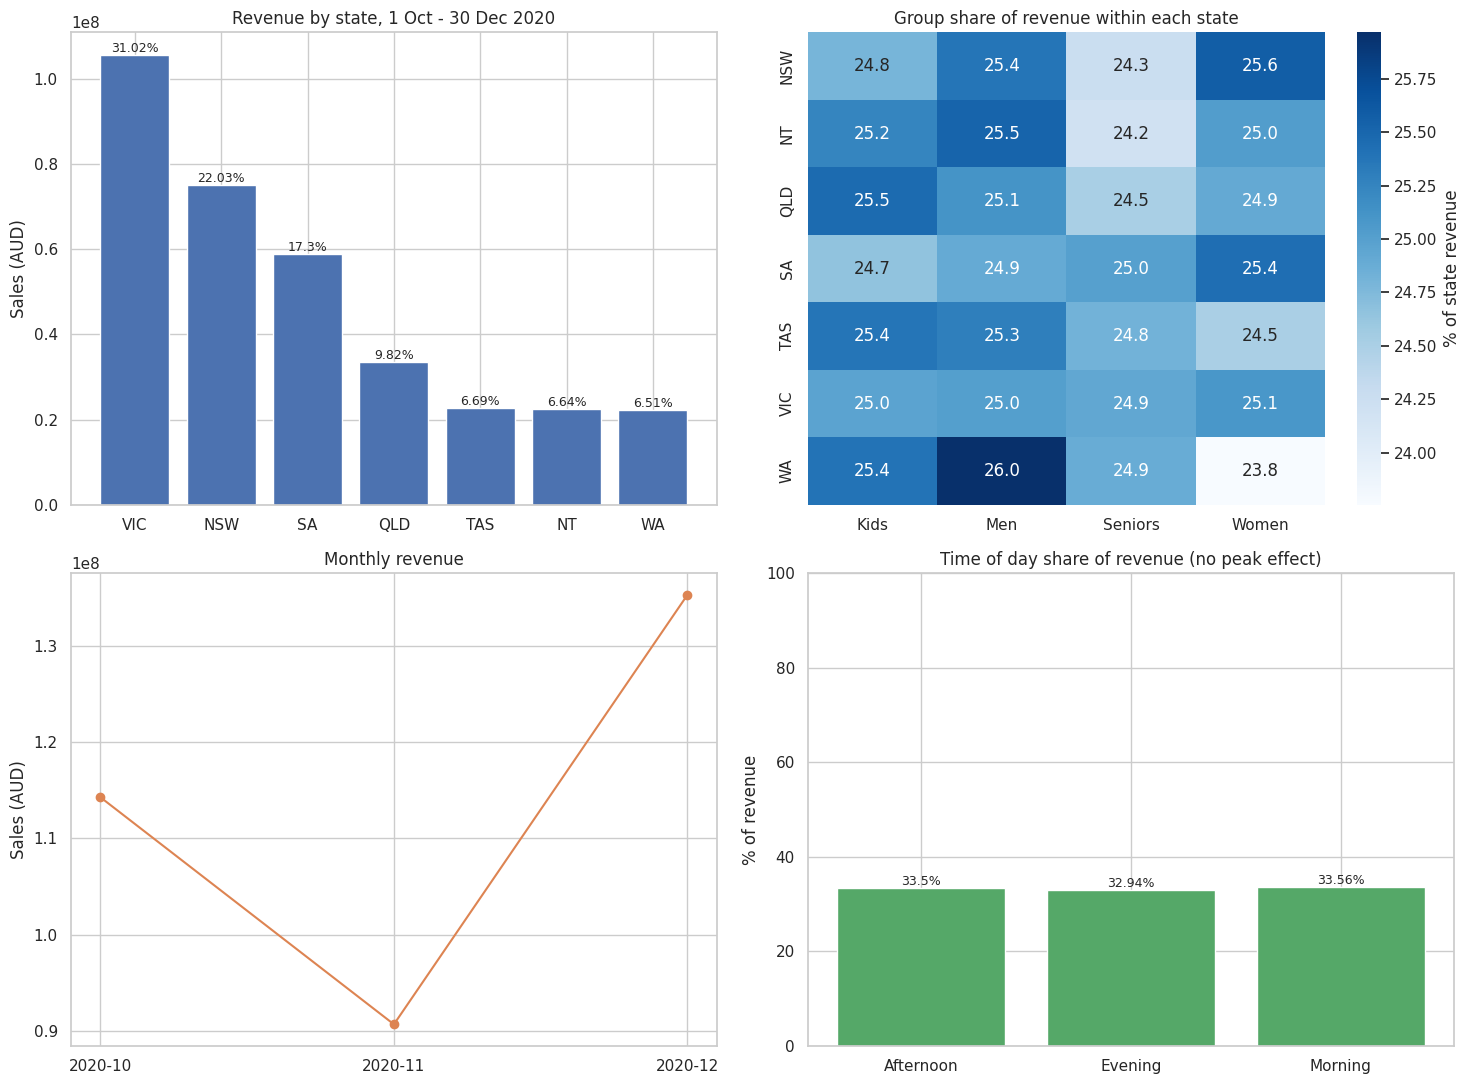

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: revenue by state with share labels
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False)
share = (state_sales / state_sales.sum() * 100).round(2)
bars = axes[0, 0].bar(state_sales.index, state_sales.values, color="#4C72B0")
axes[0, 0].set_title("Revenue by state, 1 Oct - 30 Dec 2020")
axes[0, 0].set_ylabel("Sales (AUD)")
for bar, s in zip(bars, share.values):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f"{s}%", ha="center", va="bottom", fontsize=9)

# Panel 2: state by group heatmap (share of state revenue)
sg = df.pivot_table(index="State", columns="Group", values="Sales", aggfunc="sum")
sg_pct = sg.div(sg.sum(axis=1), axis=0) * 100
sns.heatmap(sg_pct, annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={"label": "% of state revenue"}, ax=axes[0, 1])
axes[0, 1].set_title("Group share of revenue within each state")
axes[0, 1].set_ylabel("")
axes[0, 1].set_xlabel("")

# Panel 3: monthly revenue
month_sales = df.groupby("Month")["Sales"].sum()
axes[1, 0].plot(month_sales.index.astype(str), month_sales.values,
                marker="o", color="#DD8452")
axes[1, 0].set_title("Monthly revenue")
axes[1, 0].set_ylabel("Sales (AUD)")

# Panel 4: time of day, on a full 0-100 scale so the flatness is visible
time_sales = df.groupby("Time")["Sales"].sum()
time_share = (time_sales / time_sales.sum() * 100).round(2)
axes[1, 1].bar(time_share.index, time_share.values, color="#55A868")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("Time of day share of revenue (no peak effect)")
axes[1, 1].set_ylabel("% of revenue")
for i, v in enumerate(time_share.values):
    axes[1, 1].text(i, v, f"{v}%", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


#### Dashboard findings

Three states carry just over 70 percent of the quarter: VIC at 31.02 percent of revenue, NSW 22.03 and SA 17.30. WA is smallest at 6.51.


Panel 2 shows the group mix does not change by state. Every row of the heatmap sits between roughly 24 and 26 percent, so Kids, Men, Women and Seniors take a similar share of revenue in VIC as they do in WA.

Panel 3 shows the November dip and the December climb, matching the weekly view.

Panel 4 shows three bars of nearly equal height on a full 0 to 100 scale. Time of day does not separate revenue.

Across the four panels, the dashboard shows where revenue sits and which
measures actually vary. State and time of year vary. Customer group and time of day do not, and price does not vary at all.


#### Distribution plot

A distribution plot with a density curve shows the shape of Unit, which the box plot could only summarise.

The curve is overlaid so the right skew reads as a shape rather than being
inferred from where the median line sits.


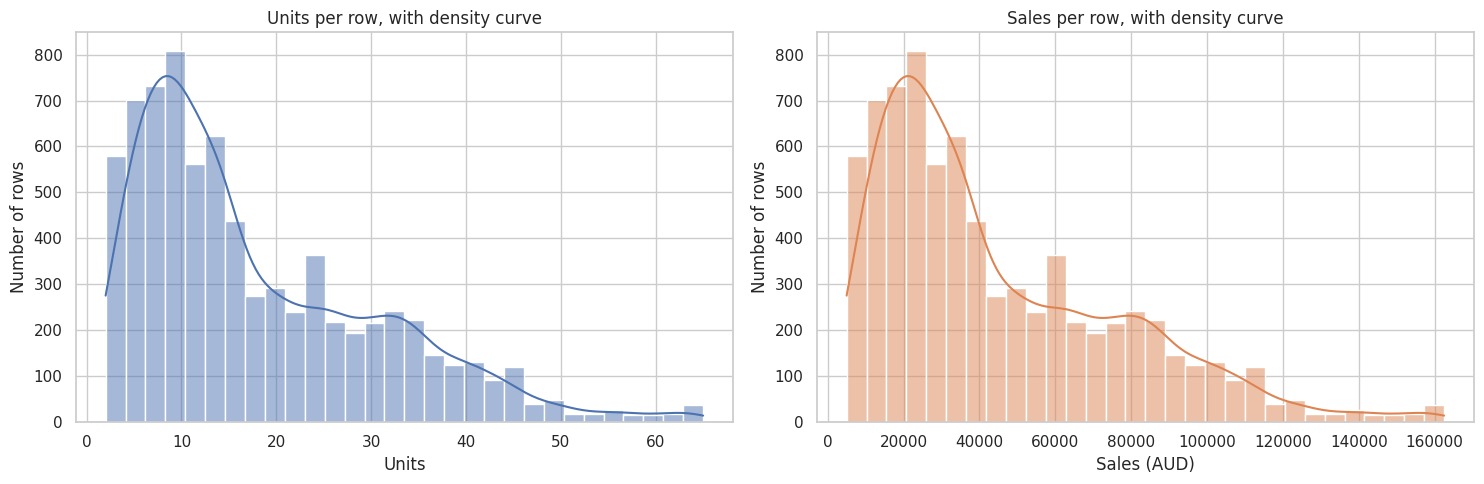

count    7560.000000
mean       18.005423
std        12.901403
min         2.000000
25%         8.000000
50%        14.000000
75%        26.000000
max        65.000000
Name: Unit, dtype: float64


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df["Unit"], bins=30, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Units per row, with density curve")
axes[0].set_xlabel("Units")
axes[0].set_ylabel("Number of rows")

sns.histplot(df["Sales"], bins=30, kde=True, color="#DD8452", ax=axes[1])
axes[1].set_title("Sales per row, with density curve")
axes[1].set_xlabel("Sales (AUD)")
axes[1].set_ylabel("Number of rows")

plt.tight_layout()
plt.show()
print(df["Unit"].describe())


#### Distribution plot findings

The peak of the density curve sits between about 10 and 20 units, with a long
tail stretching out to 65. The median is 14 and the mean is 18, so the bulk of
the business sits below the average.

The tail is thin but long. Row counts fall from around 370 at 6 units to 9 at
61 units, so the high volume rows are rare individually but numerous enough
together to lift the mean.

This is the third view of the same shape, after the summary statistics and the
box plot. The skew appears in all three, so it is a property of the data rather
than of one method.

The practical consequence is that the median describes a typical transaction and
the mean describes an average that only the top of the distribution reaches.


### Step 4(b) - Making the charts readable

A few rules are applied to every figure here.

Numbers on the bars. Percentages are printed directly, so nothing has to be
guessed from a bar height.

Scales that don't exaggerate. The time of day panel runs 0 to 100 percent, so three nearly equal values look nearly equal. Cutting the axis would make a 0.62 point gap look like a peak.

Not colour alone. Panels are labelled directly and the heatmap carries its
values, so everything still reads in black and white.

Titles that say the finding. "Time of day share of revenue (no peak effect)"
tells the reader the answer. "Revenue by time" leaves them to guess.

The flat panel stays in, since a chart showing no effect is still a result.

Three weeks are shorter than seven days, so their totals cannot be compared with a full week. The average per day puts every week on the same footing.


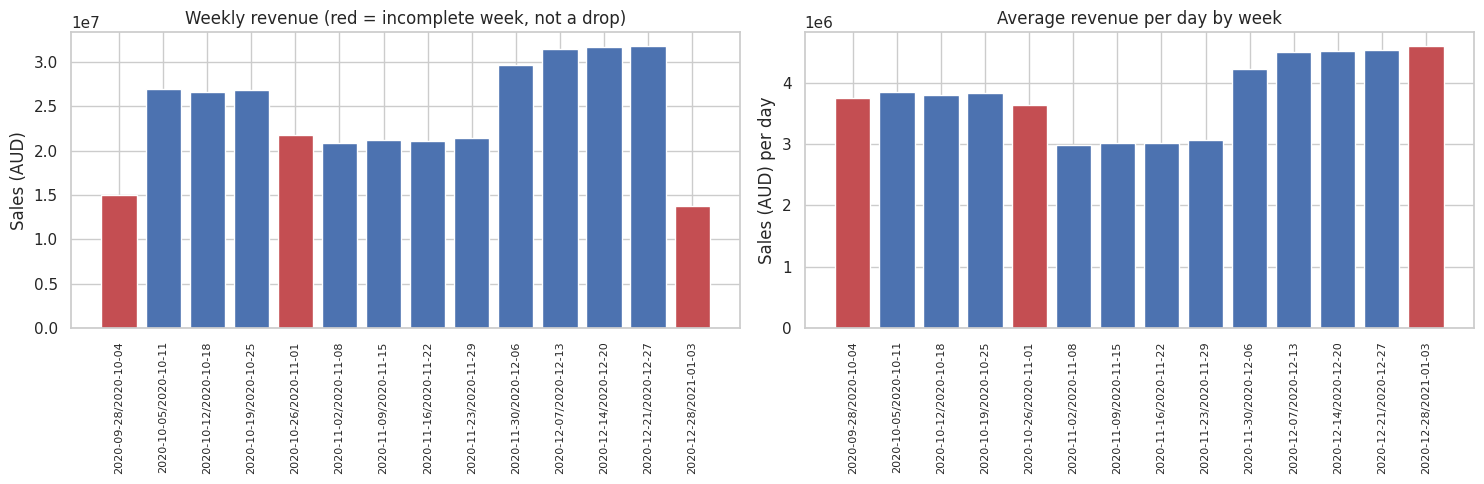

                          sales  days  weekly_avg  full_week
Week                                                        
2020-09-28/2020-10-04  15045000     4   3761250.0      False
2020-10-05/2020-10-11  27002500     7   3857500.0       True
2020-10-12/2020-10-18  26640000     7   3805714.0       True
2020-10-19/2020-10-25  26815000     7   3830714.0       True
2020-10-26/2020-11-01  21807500     6   3634583.0      False
2020-11-02/2020-11-08  20865000     7   2980714.0       True
2020-11-09/2020-11-15  21172500     7   3024643.0       True
2020-11-16/2020-11-22  21112500     7   3016071.0       True
2020-11-23/2020-11-29  21477500     7   3068214.0       True
2020-11-30/2020-12-06  29622500     7   4231786.0       True
2020-12-07/2020-12-13  31525000     7   4503571.0       True
2020-12-14/2020-12-20  31655000     7   4522143.0       True
2020-12-21/2020-12-27  31770000     7   4538571.0       True
2020-12-28/2021-01-03  13792500     3   4597500.0      False
incomplete weeks: ['2020

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# weekly revenue, with incomplete weeks flagged
wk = df.groupby("Week").agg(sales=("Sales", "sum"), days=("Date", "nunique"))
wk["weekly_avg"] = wk["sales"] / wk["days"]
wk["full_week"] = wk["days"] == 7

colors = ["#4C72B0" if full else "#C44E52" for full in wk["full_week"]]
axes[0].bar(wk.index.astype(str), wk["sales"].values, color=colors)
axes[0].set_title("Weekly revenue (red = incomplete week, not a drop)")
axes[0].set_ylabel("Sales (AUD)")
axes[0].tick_params(axis="x", rotation=90, labelsize=8)

# the same weeks as an average per day, so they compare properly
axes[1].bar(wk.index.astype(str), wk["weekly_avg"].values, color=colors)
axes[1].set_title("Average revenue per day by week")
axes[1].set_ylabel("Sales (AUD) per day")
axes[1].tick_params(axis="x", rotation=90, labelsize=8)

plt.tight_layout()
plt.show()

print(wk.round(0))
print("incomplete weeks:", wk[~wk["full_week"]].index.astype(str).tolist())


#### Weekly revenue findings

The two panels disagree in a useful way. On the left, the first week looks like the weakest of the quarter at 15,045,000, and the last looks weak too at 13,792,500. Those are not weak trading weeks. They hold 4 days and 3 days.

Dividing by the number of days fixes it. The first week averages 3,762,500 a
day, which is above the two weeks around 24 Oct at 3,634,583 and 3,750,000. The last three days average 4,597,500 a day, the highest of the whole quarter.

So the December peak is real and not calendar length. The daily average climbs from around 3,700,000 in early October, dips to about 2,980,000 in early November, then rises through December to 4,597,500. That dip and recovery is the shape of the quarter.


### Step 4(c) - Choice of visualisation library

Seaborn is the recommendation for the statistical figures, with matplotlib used underneath for layout.

The reason is what the figures need to do. The box plot, the distribution plot with a density curve and the annotated heatmap are all statistical views, and each is one line in Seaborn with sensible defaults. In matplotlib the same figures need the statistical logic written by hand, which adds code without adding insight.

The defaults also matter for readability. Seaborn handles axis labels, legends and colour scaling without extra work, and it reads a whole dataframe directly, so there is no reshaping before plotting.

Matplotlib is still used for the subplot layout and the dashboards, since it
controls figure size and panel arrangement more precisely. The two libraries
work together rather than competing.


### Step 4(d) - Daily and quarterly charts

Daily and quarterly are the last two levels in the set, so all four are covered
here: daily, weekly, monthly and quarterly.

The daily view is plotted as a line rather than bars. Ninety bars would be
unreadable, and the point is the shape of the period rather than each day. The
highest and lowest days are marked so the peaks are readable without a table.

The quarterly view is a single bar. The period covers one quarter only, so there
is nothing to compare it against.


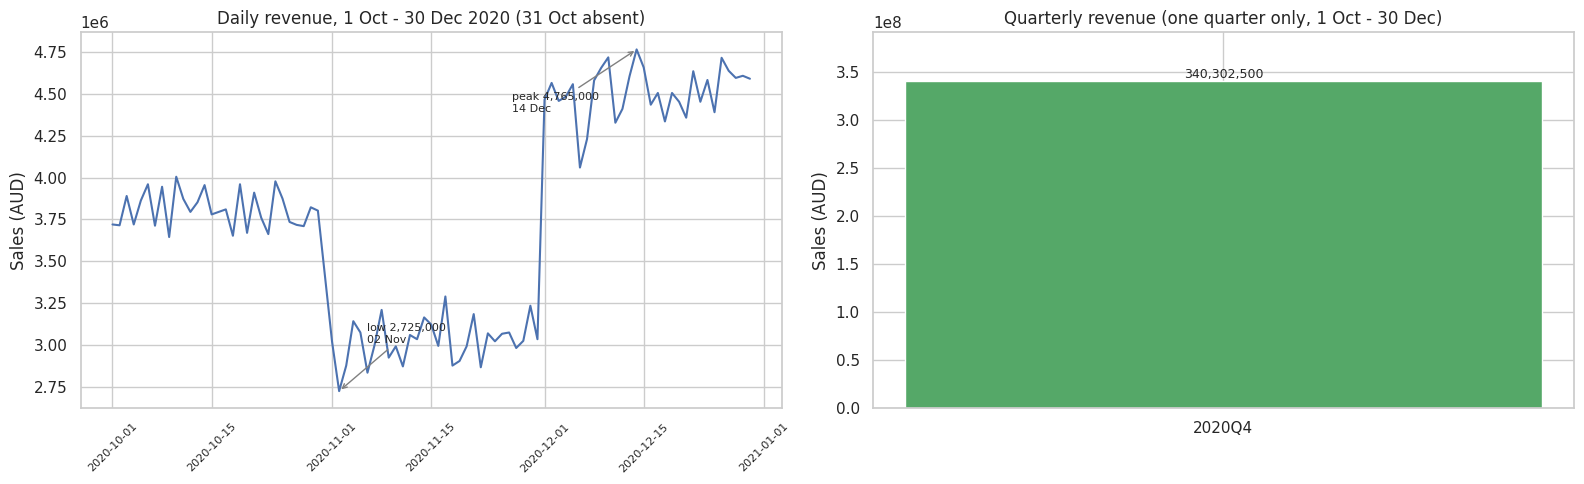

daily revenue stats:
count         90.0
mean     3781139.0
std       624887.0
min      2725000.0
25%      3086875.0
50%      3798750.0
75%      4428750.0
max      4765000.0
Name: Sales, dtype: float64
highest day: 2020-12-14 4765000
lowest day: 2020-11-02 2725000
top 5 days:
Date
2020-12-14    4765000
2020-12-10    4717500
2020-12-26    4715000
2020-12-15    4657500
2020-12-09    4655000
Name: Sales, dtype: int64
bottom 5 days:
Date
2020-11-02    2725000
2020-11-06    2835000
2020-11-22    2867500
2020-11-11    2872500
2020-11-18    2877500
Name: Sales, dtype: int64
quarterly:
Quarter
2020Q4    340302500
Freq: Q-DEC, Name: Sales, dtype: int64


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# daily revenue
daily = df.groupby("Date")["Sales"].sum()
axes[0].plot(daily.index, daily.values, color="#4C72B0", linewidth=1.5)
axes[0].set_title("Daily revenue, 1 Oct - 30 Dec 2020 (31 Oct absent)")
axes[0].set_ylabel("Sales (AUD)")
axes[0].tick_params(axis="x", rotation=45, labelsize=8)

# mark the highest day
peak_day = daily.idxmax()
axes[0].annotate(f"peak {int(daily.max()):,}\n{peak_day:%d %b}",
                 xy=(peak_day, daily.max()),
                 xytext=(-90, -45), textcoords="offset points",
                 fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="grey"))

# mark the lowest day
low_day = daily.idxmin()
axes[0].annotate(f"low {int(daily.min()):,}\n{low_day:%d %b}",
                 xy=(low_day, daily.min()),
                 xytext=(20, 35), textcoords="offset points",
                 fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="grey"))

# quarterly revenue
q = df.groupby("Quarter")["Sales"].sum()
bars = axes[1].bar(q.index.astype(str), q.values, color="#55A868", width=0.4)
axes[1].set_title("Quarterly revenue (one quarter only, 1 Oct - 30 Dec)")
axes[1].set_ylabel("Sales (AUD)")
axes[1].set_ylim(0, q.max() * 1.15)
for bar, v in zip(bars, q.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v, f"{v:,.0f}",
                 ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

print("daily revenue stats:")
print(daily.describe().round(0))
print("highest day:", peak_day.date(), int(daily.max()))
print("lowest day:", low_day.date(), int(daily.min()))
print("top 5 days:")
print(daily.sort_values(ascending=False).head(5).round(0))
print("bottom 5 days:")
print(daily.sort_values().head(5).round(0))
print("quarterly:")
print(q)


### Step 4(d) - Daily and quarterly findings

Daily revenue averages 3,781,139 across the 90 days, with a standard deviation of 624,887. Values run from 2,725,000 to 4,765,000.

The strongest day is 14 December at 4,765,000. The weakest is 2 November at
2,725,000, so the best day is about 75 percent higher than the worst, against a daily standard deviation of 624,887.

All five strongest days fall in December, on the 14th, 10th, 26th, 15th and 9th.
All five weakest fall in November, on the 2nd, 6th, 22nd, 11th and 18th. The
month to month difference is a broad shift rather than one unusual day at each end.

The shape matches the weekly view. October holds a steady band, the first half of November drops to the low 3 millions with the minimum on 2 November, and December lifts to around 4.5 million and stays there.

One detail the weekly view could not show. The move into December is a step
rather than a climb. Revenue goes from the low 3 millions in mid November to
around 4.6 million by early December and then holds high, so the quarter changes level instead of rising steadily.

The quarterly bar is a single value, 340,302,500. There is no second quarter to compare it with, so it confirms the total rather than showing a trend.

All four levels are now covered. Weekly and monthly sit on the dashboard, and daily and quarterly sit here, since ninety daily points and a single quarterly bar would crowd the panels.


### Step 5(a) - Recommendations

Recommendation 1: concentrate on volume, not price.

Every row in this dataset is priced at exactly 2500 per unit, so revenue is units multiplied by 2500 and nothing else. There is no discounting, no premium line and no price variation between states. Any growth therefore has to come from selling more units, not from changing what is charged.

Recommendation 2: treat VIC, NSW and SA as the established markets.

These three states carry 70.35 percent of the quarter's revenue on the same number of records as every other state. VIC averages 39.1 units per row against WA's 8.2, and VIC is the top state on all 90 days. The pattern is consistent across the whole period, so the base is worth protecting first: a small percentage gain here is worth more than a large percentage gain in a small state.

Recommendation 3: handle QLD, TAS, NT and WA as one group, not four.

Revenue shares run 9.82, 6.69, 6.64 and 6.51 percent, and the bottom three are within about 2,500 of each other on daily average. The three are close enough that separate plans would be hard to justify from this data. One programme aimed at raising units per transaction across the group is better justified than three separate plans that would each be built on noise.

Recommendation 4: build the calendar around the November dip, not December.

December already outperforms on its own. Daily revenue runs about 2,980,000 in early November and 4,597,500 in the final days of December, and every state gains in December without help. Early November is the weakest stretch of the quarter, while December performs without support.

Recommendation 5: do not build day-part personalisation on this data.

Morning, Afternoon and Evening take 33.56, 33.50 and 32.94 percent of revenue. That is uniform nationally, in all seven states and in all four customer groups. There is no peak to target. A next-best-offer programme timed to the morning would be built on a 0.62 point difference, which is not a signal.

Recommendation 6: report on the median, and on the spread.

Half of all transactions fall below 35,000, while the average is 45,014. The middle half of the business spans 8 to 26 units. Performance targets set on the mean will be unreachable for most transactions, and store or state comparisons on averages alone will hide a threefold spread.

One limitation belongs with these recommendations. The file is a balanced grid of 90 dates, 7 states, 4 groups and 3 day-parts at a single price, which is not how a real retailer's transaction data looks. The state differences are consistent across all 90 days, but they may reflect how the source was assembled rather than trading strength in the market. Before any budget moves on the back of this analysis, the same questions should be asked of real transaction data with price, cost and store columns attached.


### Step 5(b) - Conclusion

The analysis covers 1 Oct to 30 Dec 2020, 90 trading days across seven states, four customer groups and three day-parts, with 31 Oct missing from the source.

Four things came out of it.

Revenue is concentrated by state. VIC holds 31.02 percent of the quarter, and VIC, NSW and SA together hold 70.35 percent. VIC is the top state on all 90 days, and five of the other six never reach VIC's weakest day, so the separation is consistent rather than driven by a few strong days.

The demography is flat. Men, Women, Kids and Seniors take 25.20, 25.11, 25.00 and 24.69 percent of revenue, and the group mix inside each state is the same. Customer group is not a useful way to split the market here.

Time of day is flat. Three separate checks, at national, state and group level, all give an even third. No peak, no off-peak.

December is the strongest month. Every state improves against October, the daily average climbs from about 2,980,000 in early November to 4,597,500 in the last days of December, and that peak survives once uneven week lengths are removed.

Two structural facts shape all of it. Price is fixed at 2500 per unit on every row, so revenue is units multiplied by 2500 and no price or margin analysis is possible. And the file is a balanced design at that single price, which is consistent with the flat demographic and day-part results rather than proving them.
The usable levers are volume and the December peak. Price cannot be tested because it does not vary, the customer groups are evenly spread, the day-parts are evenly spread, and the state ranking is clear but may be a property of the source rather than of the market.
